In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

1.Load the dataset

In [3]:
df = pd.read_csv("Advertising.csv")

In [4]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [5]:
df.columns

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')

In [6]:
df.shape

(200, 4)

In [7]:
df.dtypes

TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object

In [8]:
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [9]:
df = df.drop(columns=['Unnamed: 0'], errors='ignore')

In [10]:
df.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


2 — Use TV, Radio, and Newspaper as input features

In [11]:
X = df[['TV', 'Radio', 'Newspaper']]
X.head()

,TV,Radio,Newspaper
0,230.1,37.8,69.2
1,44.5,39.3,45.1
2,17.2,45.9,69.3
3,151.5,41.3,58.5
4,180.8,10.8,58.4


3 — Use Sales as the target variable

In [12]:
y = df['Sales']
y.head()

0    22.1
1    10.4
2    12.0
3    16.5
4    17.9
Name: Sales, dtype: float64

4 — Build the Multiple Linear Regression model

In [13]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

5 — Train the model using historical data

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [15]:
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


6 — Predict Sales for unseen data points

In [16]:
y_pred = model.predict(X_test)

print("Predicted Sales:")
print(y_pred)

Predicted Sales:
[17.0347724  20.40974033 23.72398873  9.27278518 21.68271879 12.56940161
 21.08119452  8.69035045 17.23701254 16.66657475  8.92396497  8.4817344
 18.2075123   8.06750728 12.64550975 14.93162809  8.12814594 17.89876565
 11.00880637 20.47832788 20.80631846 12.59883297 10.9051829  22.38854775
  9.41796094  7.92506736 20.83908497 13.81520938 10.77080925  7.92682509
 15.95947357 10.63490851 20.80292008 10.43434164 21.5784752  21.18364487
 12.12821771 22.80953262 12.60992766  6.46441252]


7 — Predict Sales for TV = 150, Radio = 20, Newspaper = 30

In [17]:
new_data = pd.DataFrame({
    'TV': [150],
    'Radio': [20],
    'Newspaper': [30]
})

prediction = model.predict(new_data)

print("Predicted Sales:", prediction[0])

Predicted Sales: 15.039523680317233


8 — Evaluate the model's prediction error

In [18]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 1.274826210954934
MSE: 2.907756910271091
RMSE: 1.7052146229349228
R2 Score: 0.9059011844150826


9 — Interpret the model coefficients

In [19]:
print("Intercept:", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 4.714126402214134
TV : 0.05450927083721976
Radio : 0.10094536239295573
Newspaper : 0.004336646822034021


In [20]:
coefficients = pd.Series(model.coef_, index=X.columns)

print("Strongest impact:", coefficients.abs().idxmax())
print("Least impact:", coefficients.abs().idxmin())

Strongest impact: Radio
Least impact: Newspaper


10 — Visualize Actual Sales vs Predicted Sales

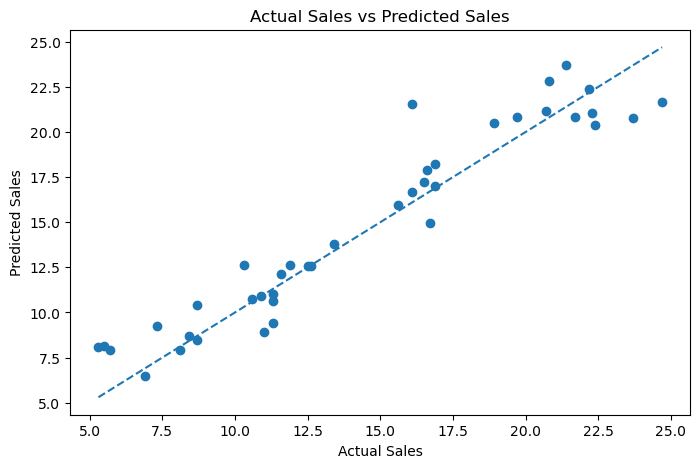

In [21]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual Sales vs Predicted Sales")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.show()

11 — Business recommendation and technical improvement

Business Recommendation:

Based on the analysis, the company should give greater attention to the advertising medium showing the strongest relationship with Sales. The company can use the prediction model to test different advertising budget combinations before making final spending decisions.

Technical Improvement:

Prediction accuracy can be improved by using cross-validation and comparing different regression models such as Linear Regression, Ridge Regression, and Lasso Regression. Additional relevant features can also be included if available.